<a href="https://colab.research.google.com/github/Nidhiisinhaaa/NLP-EXPERIMENTS-SEM-7/blob/main/EXP_8_Chunking_in_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>




**Implementing chunking using NLTK , SpaCy , Stanza in Python**


>

NLTK

POS Tags:
[('A', 'DT'), ('beautiful', 'JJ'), ('girl', 'NN'), ('is', 'VBZ'), ('reading', 'VBG'), ('a', 'DT'), ('book', 'NN'), ('.', '.')]

Chunk Tree:
(S
  A/DT
  (NP beautiful/JJ girl/NN)
  is/VBZ
  reading/VBG
  (NP a/DT book/NN)
  ./.)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


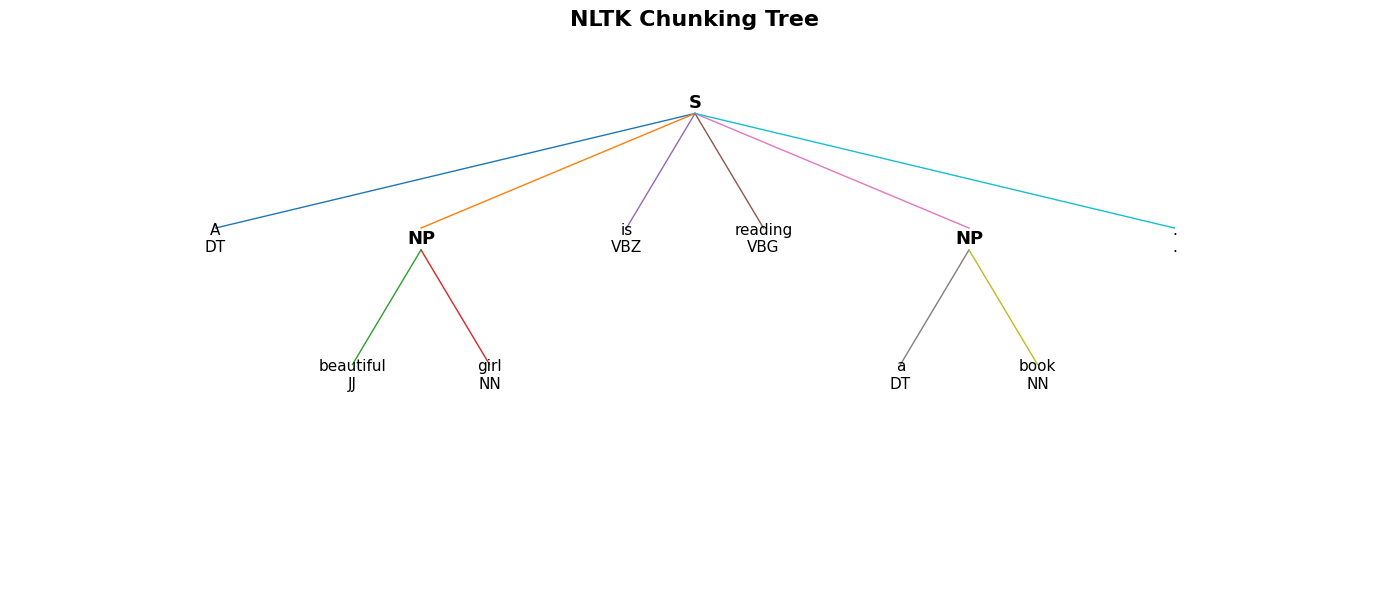

In [ ]:
import nltk
import matplotlib.pyplot as plt

# Download required NLTK packages
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

# --------------------------------
# INPUT
# --------------------------------

sentence = "A beautiful girl is reading a book."

# Tokenization
words = nltk.word_tokenize(sentence)

# POS Tagging
tagged_words = nltk.pos_tag(words)

print("POS Tags:")
print(tagged_words)

# --------------------------------
# CHUNKING
# --------------------------------

grammar = r"""
    NP: {<DT><NN.*>}
    NP: {<JJ><NN.*>}
"""

chunk_parser = nltk.RegexpParser(grammar)

tree = chunk_parser.parse(tagged_words)

print("\nChunk Tree:")
print(tree)

# --------------------------------
# GRAPHICAL TREE
# --------------------------------

def get_width(node):

    # POS tuple such as ('The', 'DT')
    if isinstance(node, tuple):
        return 1

    # Normal word
    if isinstance(node, str):
        return 1

    # NLTK Tree
    return sum(get_width(child) for child in node)


def draw_node(ax, node, x, y, parent_x=None, parent_y=None):

    # -----------------------------
    # Leaf: POS tuple
    # -----------------------------
    if isinstance(node, tuple):

        word, tag = node

        label = f"{word}\n{tag}"

        # Connection from parent
        if parent_x is not None:
            ax.plot(
                [parent_x, x],
                [parent_y - 0.08, y + 0.08],
                linewidth=1
            )

        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=11
        )

        return

    # -----------------------------
    # Leaf: string
    # -----------------------------
    if isinstance(node, str):

        if parent_x is not None:
            ax.plot(
                [parent_x, x],
                [parent_y - 0.08, y + 0.08],
                linewidth=1
            )

        ax.text(
            x,
            y,
            node,
            ha="center",
            va="center",
            fontsize=11
        )

        return

    # -----------------------------
    # NLTK Tree Node
    # -----------------------------

    if parent_x is not None:
        ax.plot(
            [parent_x, x],
            [parent_y - 0.08, y + 0.08],
            linewidth=1
        )

    # Draw node label
    ax.text(
        x,
        y,
        node.label(),
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold"
    )

    children = list(node)

    widths = [get_width(child) for child in children]

    total_width = sum(widths)

    current_x = x - total_width / 2

    for child, width in zip(children, widths):

        child_x = current_x + width / 2

        draw_node(
            ax,
            child,
            child_x,
            y - 1,
            x,
            y
        )

        current_x += width


# --------------------------------
# CREATE GRAPH
# --------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.axis("off")

tree_width = get_width(tree)

draw_node(
    ax,
    tree,
    0,
    0
)

ax.set_xlim(
    -tree_width / 2 - 1,
    tree_width / 2 + 1
)

ax.set_ylim(
    -3.5,
    0.5
)

plt.title(
    "NLTK Chunking Tree",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

SpaCy  

In [ ]:
!pip install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 71.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import spacy
from spacy import displacy

# Load English model
nlp = spacy.load("en_core_web_sm")

# Input sentence
sentence = "A beautiful girl is reading a book."

# Process sentence
doc = nlp(sentence)

# Print POS tags
print("POS Tags:")
for token in doc:
    print(token.text, token.pos_, token.tag_)

# Print noun chunks
print("\nNoun Chunks:")
for chunk in doc.noun_chunks:
    print(chunk.text)

# Display graphical dependency tree
displacy.render(doc, style="dep", jupyter=True)

POS Tags:
A DET DT
beautiful ADJ JJ
girl NOUN NN
is AUX VBZ
reading VERB VBG
a DET DT
book NOUN NN
. PUNCT .

Noun Chunks:
A beautiful girl
a book


**Stanza**

In [ ]:
!pip install stanza
import stanza

stanza.download('en')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 794.2/794.2 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 418.7/418.7 kB 22.8 MB/s eta 0:00:00


INFO:stanza:Downloaded file to /root/.cache/stanza/1.14.0/resources/resources.json
INFO:stanza:Downloading default packages for language: en (English) ...


models/default.zip: reconstructing file:   0%|          |  0.00B /  525MB            

models/default.zip: downloading bytes:           |  0.00B            

INFO:stanza:Downloaded file to /root/.cache/stanza/1.14.0/resources/en/default.zip
INFO:stanza:Finished downloading models and saved to /root/.cache/stanza/1.14.0/resources


[['zip', 'default.zip']]

In [ ]:
!pip install graphviz

In [ ]:
import stanza

stanza.download("en")

INFO:stanza:Downloaded file to /root/.cache/stanza/1.14.0/resources/resources.json
INFO:stanza:Downloading default packages for language: en (English) ...
INFO:stanza:File exists: /root/.cache/stanza/1.14.0/resources/en/default.zip
INFO:stanza:Finished downloading models and saved to /root/.cache/stanza/1.14.0/resources


[['zip', 'default.zip']]

INFO:stanza:Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


INFO:stanza:Downloaded file to /root/.cache/stanza/1.14.0/resources/resources.json
INFO:stanza:Loading these models for language: en (English):
| Processor | Package           |
---------------------------------
| tokenize  | combined_nocharlm |
| mwt       | combined          |
| pos       | combined_charlm   |
| lemma     | combined_nocharlm |
| depparse  | combined_charlm   |

INFO:stanza:Using device: cpu
INFO:stanza:Loading: tokenize
INFO:stanza:Loading: mwt
INFO:stanza:Loading: pos
INFO:stanza:Loading: lemma
INFO:stanza:Loading: depparse
INFO:stanza:Done loading processors!


POS Tags:
A DET DT
beautiful ADJ JJ
girl NOUN NN
is AUX VBZ
reading VERB VBG
a DET DT
book NOUN NN
. PUNCT .

Dependency Relations:
1 A Head: 3 Relation: det
2 beautiful Head: 3 Relation: amod
3 girl Head: 5 Relation: nsubj
4 is Head: 5 Relation: aux
5 reading Head: 0 Relation: root
6 a Head: 7 Relation: det
7 book Head: 5 Relation: obj
8 . Head: 5 Relation: punct


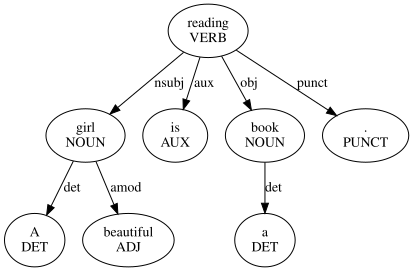

In [ ]:
import stanza
from graphviz import Digraph

# Create Stanza NLP pipeline
nlp = stanza.Pipeline(
    lang="en",
    processors="tokenize,pos,lemma,depparse"
)

# Input sentence
sentence = "A beautiful girl is reading a book."

# Process sentence
doc = nlp(sentence)

# -----------------------------
# POS TAGGING
# -----------------------------

print("POS Tags:")

for sent in doc.sentences:
    for word in sent.words:
        print(
            word.text,
            word.upos,
            word.xpos
        )

# -----------------------------
# DEPENDENCY RELATIONS
# -----------------------------

print("\nDependency Relations:")

for sent in doc.sentences:
    for word in sent.words:
        print(
            word.id,
            word.text,
            "Head:",
            word.head,
            "Relation:",
            word.deprel
        )

# -----------------------------
# CREATE GRAPH
# -----------------------------

dot = Digraph(
    name="Stanza Dependency Tree",
    format="png"
)

dot.attr(
    rankdir="TB",
    size="12"
)

# Add nodes
for sent in doc.sentences:

    for word in sent.words:

        label = f"{word.text}\n{word.upos}"

        dot.node(
            str(word.id),
            label
        )

# Add dependency edges
for sent in doc.sentences:

    for word in sent.words:

        if word.head != 0:

            dot.edge(
                str(word.head),
                str(word.id),
                label=word.deprel
            )

# Display graph
dot